# Introduction to Natural Language Processing: Assignment 2

In this exercise we'll practice features extraction using Tf-Idf and SpaCy as well as multiclass text classification using the word embedding technique.

- You can use built-in Python packages, spaCy, scikit-learn, Numpy and Pandas.
- Please comment your code
- Submissions are due Tuesdays at 23:59 AoE **only** on eCampus: **Assignmnets >> Student Submissions >> Assignment 2**

- Name the file aproppriately: "Assignment_2_\<Your_Name\>.ipynb" and submit only the Jupyter Notebook file.
- If you are working in a group of two, please have the names of both of the members in the file name.
- Please use relative path, your code should work on my computer if the Jupyter Notebook and the file are both in the same directory.

Example: file_name = bbc-news.csv, **DON'T use:** /Users/ComputerName/Username/Documents/.../bbc-news.csv

### Task 1 (2 points)

Write a function `extract_proper_nouns(my_file_name)` that takes a file name (my_file_name.txt) as input and returns a list containing all proper nouns with more than one token.

**Example:**

text = "Hong Kong and Japan are two countries in Asia and New York is the largest city in the world"

return = `["New York", "Hong Kong"]` **(Note: it should not return "Japan")**

In [11]:
!python -m spacy download en_core_web_sm

  Using cached en_core_web_sm-3.8.0-py3-none-any.whl (12.8 MB)
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


In [12]:
# Importing key libraries
import spacy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [13]:
def extract_proper_nouns(my_file_name):
 
    with open(my_file_name, "r", encoding="utf-8") as text_file:
        text = text_file.read()

    nlp = spacy.load("en_core_web_sm")
    doc = nlp(text)

    several_token_propn = []
    seen = set()
    index = 0

    # SpaCy labels each word of a multi-word proper noun as PROPN.
    while index < len(doc):
        if doc[index].pos_ != "PROPN":
            index += 1
            continue

        start = index
        while index < len(doc) and doc[index].pos_ == "PROPN":
            index += 1

        # A proper noun is kept only when it consists of more than one token.
        if index - start > 1:
            proper_noun = doc[start:index].text
            if proper_noun not in seen:
                seen.add(proper_noun)
                several_token_propn.append(proper_noun)

    return several_token_propn

### Task 2 (3 points)

Write a function `common_lemma(my_file_name)` that takes a file name (my_file_name.txt) as input and returns a Python dictionary with lemmas as `key` and the `value` that should contain a list with both verbs and nouns sharing the same lemma.

**Examples:**

1.
text = "When users google for a word or any query, their system internally runs a pipeline in order to process what the person is querying."

return = `{"query": ["query", "querying"]}`

2.
text = I really loved the movie and show, the movie was showing reality but it showed sometimes nonesense!

return = `{"show": ["show", "showing", "showed"]}` **(Note: it should not return "movie" because both "movie"s are NOUN)**

In [14]:
def common_lemma(my_file_name):

    tokens_with_common_lemma = {}

    with open(my_file_name, "r", encoding="utf-8") as text_file:
        text = text_file.read()

    nlp = spacy.load("en_core_web_sm")
    doc = nlp(text)
    lemma_groups = {}

    # Keep surface forms and POS tags together so repeated nouns alone do not qualify.
    for token in doc:
        if token.pos_ not in {"NOUN", "VERB"}:
            continue

        lemma = token.lemma_
        if lemma not in lemma_groups:
            lemma_groups[lemma] = {"forms": [], "pos": set()}

        group = lemma_groups[lemma]
        if token.text not in group["forms"]:
            group["forms"].append(token.text)
        group["pos"].add(token.pos_)

    for lemma, group in lemma_groups.items():
        if group["pos"] == {"NOUN", "VERB"}:
            tokens_with_common_lemma[lemma] = group["forms"]

    return(tokens_with_common_lemma)

### Task 3 (1 point)

Load the data `bbc-text.csv`; This datata consists of 2225 documents from the BBC news website corresponding to stories from 2004-2005.

In [15]:
import pandas as pd

bbc_data = pd.read_csv("bbc-news.csv")
bbc_data.head()

,category,text
0,tech,tv future in the hands of viewers with home th...
1,business,worldcom boss left books alone former worldc...
2,sport,tigers wary of farrell gamble leicester say ...
3,sport,yeading face newcastle in fa cup premiership s...
4,entertainment,ocean s twelve raids box office ocean s twelve...


### Task 4 (1 point)

Show how many articles we have for each topical area (class label) in the dataset using a plot.

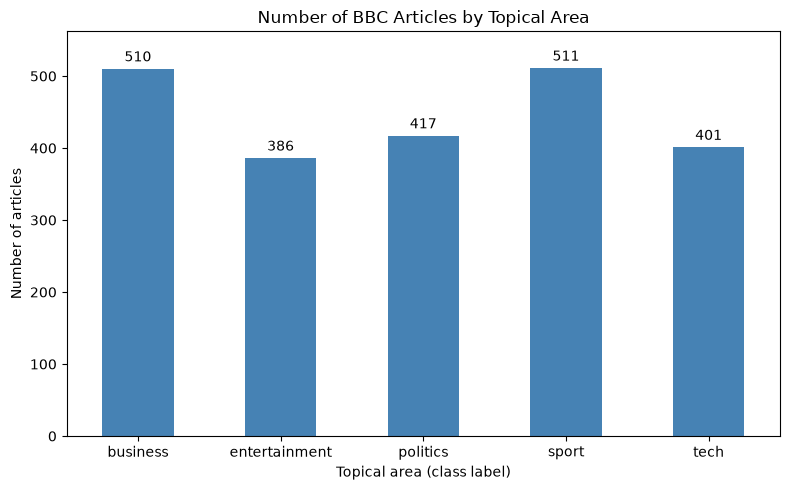

In [16]:
# Count articles for each class label.
category_counts = bbc_data["category"].value_counts().sort_index()

ax = category_counts.plot(kind="bar", figsize=(8, 5), color="steelblue")
ax.set_title("Number of BBC Articles by Topical Area")
ax.set_xlabel("Topical area (class label)")
ax.set_ylabel("Number of articles")
ax.bar_label(ax.containers[0], fmt="%d", padding=3)
ax.set_ylim(0, category_counts.max() * 1.1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Task 5 (2 point)

Preprocessing: Define two following functions and apply them to the dataset:
1. Remove punctuation
2. Remove any numbers

In [17]:
import unicodedata

def remove_punctuation(corpus):
    return corpus.apply(
        lambda text: "".join(
            character for character in text
            if not unicodedata.category(character).startswith("P")
        )
    )

def remove_numbers(corpus):
    return corpus.apply(
        lambda text: "".join(character for character in text if not character.isnumeric())
    )

bbc_data["text"] = remove_numbers(remove_punctuation(bbc_data["text"]))

### Task 6.1 (1 points)

Split the data into training and test set (70% and 30%) using scikit-learn, shuffle it, and set the `seed=101 (random_state)`.

**NOTE:** If working with this dataset is not computationaly possible for you, you can work only with a subset of the dataset (i.e., the first 1000 rows) and use only the first 150 tokens for each article. You should point this out in your code.

In [18]:
from sklearn.model_selection import train_test_split

X = bbc_data["text"]
y = bbc_data["category"]

# Keep class proportions consistent across the training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=101,
    shuffle=True,
    stratify=y,
)

### Task 6.2 (3 points)

### **Training models on TF-IDF vectors:**

a) Convert each article in your data splits to a vector representation using the tf-idf-vectorizer.

b) Using the vectors from the previous step, train the `MLPClassifier` and another model of your choice from the scikit-learn library.

c) Test both of your models on the test set from Task 6.1.

In [1]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

# Fit the vectorizer on training articles only to avoid test-data leakage.
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

mlp_tfidf = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=101,
    early_stopping=True,
)
mlp_tfidf.fit(X_train_tfidf, y_train)
y_pred_MLP_tfidf = mlp_tfidf.predict(X_test_tfidf)

logistic_regression_tfidf = LogisticRegression(max_iter=1000, random_state=101)
logistic_regression_tfidf.fit(X_train_tfidf, y_train)
y_pred_LR_tfidf = logistic_regression_tfidf.predict(X_test_tfidf)

print(f"MLP TF-IDF accuracy: {accuracy_score(y_test, y_pred_MLP_tfidf):.3f}")
print(f"Logistic regression TF-IDF accuracy: {accuracy_score(y_test, y_pred_LR_tfidf):.3f}")

NameError: name 'X_train' is not defined

### Task 6.3 (3 points)

### **Training models on SpaCy model vector representation:**

a) Convert each article in your data splits to a vector representation using the pre-trained spaCy model. (**Hint:** It should be stored as an array)

b) Using the vectors from the previous step, train the `MLPClassifier` and another model of your choice from the scikit-learn library.

c) Test both of your models on the test set from Task 6.1.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.neural_network import MLPClassifier

nlp = spacy.load("en_core_web_sm")
X_train_spacy = np.vstack([doc.vector for doc in nlp.pipe(X_train, batch_size=64)])
X_test_spacy = np.vstack([doc.vector for doc in nlp.pipe(X_test, batch_size=64)])

mlp_spacy = MLPClassifier(
    hidden_layer_sizes=(100,),
    max_iter=300,
    random_state=101,
    early_stopping=True,
)
mlp_spacy.fit(X_train_spacy, y_train)
y_pred_MLP_spacy = mlp_spacy.predict(X_test_spacy)

logistic_regression_spacy = LogisticRegression(max_iter=1000, random_state=101)
logistic_regression_spacy.fit(X_train_spacy, y_train)
y_pred_LR_spacy = logistic_regression_spacy.predict(X_test_spacy)

print(f"MLP spaCy accuracy: {accuracy_score(y_test, y_pred_MLP_spacy):.3f}")
print(f"Logistic regression spaCy accuracy: {accuracy_score(y_test, y_pred_LR_spacy):.3f}")

MLP spaCy accuracy: 0.623
Logistic regression spaCy accuracy: 0.762


### Task 7 (4 points)

Using the predictions from the four classifiers, evaluate the models and report accuracy, recall, precision, f1 scores and confusion matrix for each of them. (**Hint:** You should build a confusion matrix for multi-class classification)

In [21]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_predictions = {
    "MLP (TF-IDF)": y_pred_MLP_tfidf,
    "Logistic Regression (TF-IDF)": y_pred_LR_tfidf,
    "MLP (spaCy)": y_pred_MLP_spacy,
    "Logistic Regression (spaCy)": y_pred_LR_spacy,
}
class_labels = sorted(y_test.unique())

for model_name, y_pred in model_predictions.items():
    print(f"\n{model_name}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred):.3f}")
    print(
        classification_report(
            y_test,
            y_pred,
            labels=class_labels,
            target_names=class_labels,
            zero_division=0,
            digits=3,
        )
    )

    matrix = confusion_matrix(y_test, y_pred, labels=class_labels)
    display(
        pd.DataFrame(
            matrix,
            index=pd.Index(class_labels, name="Actual"),
            columns=pd.Index(class_labels, name="Predicted"),
        )
    )


MLP (TF-IDF)
Accuracy: 0.972
               precision    recall  f1-score   support

     business      0.961     0.961     0.961       153
entertainment      1.000     0.931     0.964       116
     politics      0.976     0.968     0.972       125
        sport      0.987     1.000     0.994       154
         tech      0.937     0.992     0.964       120

     accuracy                          0.972       668
    macro avg      0.972     0.970     0.971       668
 weighted avg      0.972     0.972     0.972       668



Predicted,business,entertainment,politics,sport,tech
Actual,,,,,
business,147,0,1,1,4
entertainment,3,108,2,0,3
politics,3,0,121,0,1
sport,0,0,0,154,0
tech,0,0,0,1,119



Logistic Regression (TF-IDF)
Accuracy: 0.967
               precision    recall  f1-score   support

     business      0.960     0.941     0.950       153
entertainment      0.991     0.948     0.969       116
     politics      0.961     0.976     0.968       125
        sport      0.987     1.000     0.994       154
         tech      0.935     0.967     0.951       120

     accuracy                          0.967       668
    macro avg      0.967     0.966     0.966       668
 weighted avg      0.967     0.967     0.967       668



Predicted,business,entertainment,politics,sport,tech
Actual,,,,,
business,144,0,4,1,4
entertainment,2,110,1,0,3
politics,2,0,122,0,1
sport,0,0,0,154,0
tech,2,1,0,1,116



MLP (spaCy)
Accuracy: 0.623
               precision    recall  f1-score   support

     business      0.643     0.647     0.645       153
entertainment      0.761     0.466     0.578       116
     politics      0.518     0.352     0.419       125
        sport      0.719     0.799     0.757       154
         tech      0.513     0.800     0.625       120

     accuracy                          0.623       668
    macro avg      0.631     0.613     0.605       668
 weighted avg      0.634     0.623     0.613       668



Predicted,business,entertainment,politics,sport,tech
Actual,,,,,
business,99,3,14,5,32
entertainment,20,54,11,24,7
politics,21,1,44,17,42
sport,3,9,9,123,10
tech,11,4,7,2,96



Logistic Regression (spaCy)
Accuracy: 0.762
               precision    recall  f1-score   support

     business      0.736     0.837     0.783       153
entertainment      0.807     0.612     0.696       116
     politics      0.719     0.656     0.686       125
        sport      0.839     0.877     0.857       154
         tech      0.710     0.775     0.741       120

     accuracy                          0.762       668
    macro avg      0.762     0.751     0.753       668
 weighted avg      0.764     0.762     0.759       668



Predicted,business,entertainment,politics,sport,tech
Actual,,,,,
business,128,4,10,2,9
entertainment,13,71,10,17,5
politics,16,1,82,5,21
sport,4,6,6,135,3
tech,13,6,6,2,93
